## The lab was fulfilled by Bulyha Anastasiia group K-10 
## Variant 4
## Teacher Andrii Liashko
## pandas: 2.2.0, matplotlib: 3.8.3, python: 3.11.8

## №1

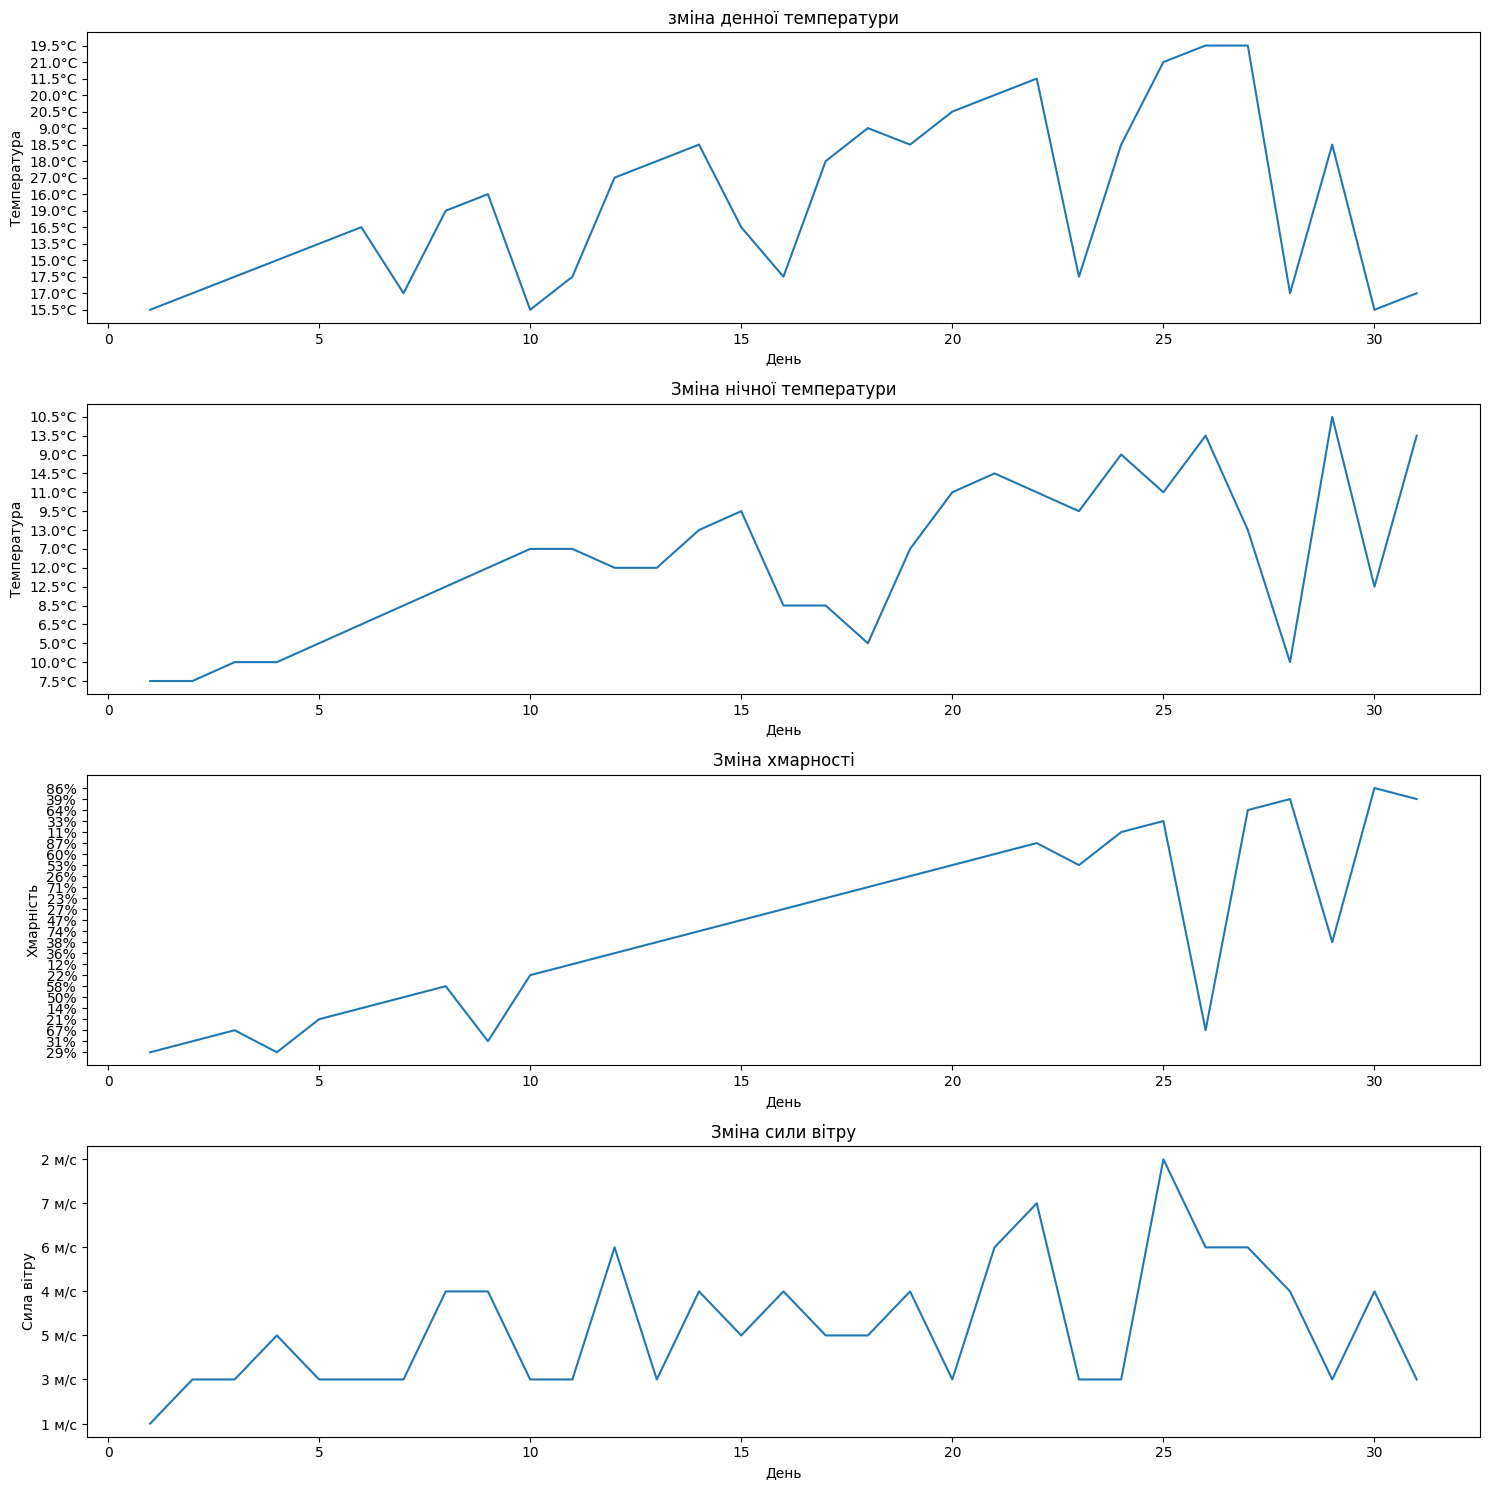

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
weather = pd.read_csv('weather.csv')
period = weather.loc[weather['період'].str.split('-').str[1].astype(int) == (4 % 12 + 1)]

fig, axs = plt.subplots(4, 1, figsize=(15, 15))

axs[0].plot(period['день'], period['денна температура повітря'])
axs[0].set_title('зміна денної температури')
axs[0].set_xlabel('День')
axs[0].set_ylabel('Температура')

axs[1].plot(period['день'], period['нічна температура повітря'])
axs[1].set_title('Зміна нічної температури')
axs[1].set_xlabel('День')
axs[1].set_ylabel('Температура')

axs[2].plot(period['день'], period['хмарність'])
axs[2].set_title('Зміна хмарності')
axs[2].set_xlabel('День')
axs[2].set_ylabel('Хмарність')

axs[3].plot(period['день'], period['сила вітру'])
axs[3].set_title('Зміна сили вітру')
axs[3].set_xlabel('День')
axs[3].set_ylabel('Сила вітру')

plt.tight_layout()
plt.show()

## №2

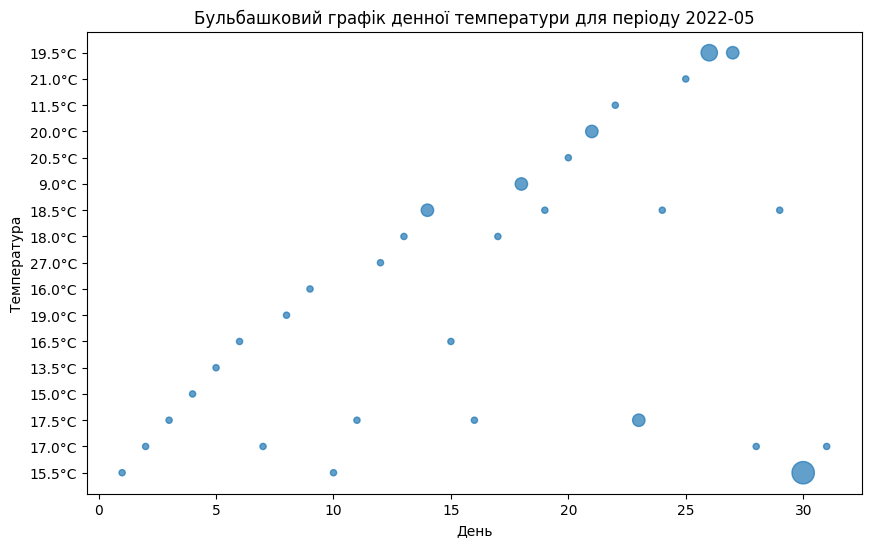

In [2]:
period.loc[period['опади'].str.split(' ').str[0] == '-', 'опади'] = '0'
rainfall = period['опади'].str.split(' ').str[0].astype(float)

plt.figure(figsize=(10, 6))
plt.scatter(period['день'], period['денна температура повітря'], s=rainfall*60 + 20, alpha=0.7)
plt.xlabel('День')
plt.ylabel('Температура')
plt.title('Бульбашковий графік денної температури для періоду 2022-05')
plt.show()

## №3

In [3]:
for i in range(1, 13):
    month = weather.loc[weather['період'].str.split('-').str[1].astype(int) == i]
    temp_diff = month['денна температура повітря'].str.split('°').str[0].astype(float).mean() - period['нічна температура повітря'].str.split('°').str[0].astype(float).mean()
    monthly_deviation = temp_diff.mean()
    print('Середнє відхилення нічної температури від денної:', monthly_deviation)

Середнє відхилення нічної температури від денної: -7.5
Середнє відхилення нічної температури від денної: -8.73905529953917
Середнє відхилення нічної температури від денної: -1.887096774193548
Середнє відхилення нічної температури від денної: 1.6811827956989251
Середнє відхилення нічної температури від денної: 7.451612903225806
Середнє відхилення нічної температури від денної: 15.014516129032257
Середнє відхилення нічної температури від денної: 15.419354838709678
Середнє відхилення нічної температури від денної: 18.274193548387096
Середнє відхилення нічної температури від денної: 5.7978494623655905
Середнє відхилення нічної температури від денної: 3.64516129032258
Середнє відхилення нічної температури від денної: -4.218817204301075
Середнє відхилення нічної температури від денної: -8.838709677419356


## №4

In [4]:
temp_diff = weather['нічна температура повітря'].str.split('°').str[0].astype(float) - weather['денна температура повітря'].str.split('°').str[0].astype(float)
max_diff_indices = temp_diff.idxmax()
print(weather.loc[max_diff_indices])

день                               6
хмарність                        85%
опади                              -
денна температура повітря     -2.5°C
нічна температура повітря      3.5°C
сила вітру                     5 м/с
період                       2023-01
Name: 94, dtype: object


## №5

In [5]:
wind_speed = period['сила вітру'].str.split('м/с').str[0].astype(float)
windiest_days_indices = wind_speed.nlargest(4).index
print(period.loc[windiest_days_indices])

     день хмарність   опади денна температура повітря  \
355    22       87%       0                    11.5°C   
345    12       36%       0                    27.0°C   
354    21       60%  1 м.м.                    20.0°C   
359    26       67%  2 м.м.                    19.5°C   

    нічна температура повітря сила вітру   період  
355                    11.0°C      7 м/с  2022-05  
345                    12.0°C      6 м/с  2022-05  
354                    14.5°C      6 м/с  2022-05  
359                    13.5°C      6 м/с  2022-05  


## №6

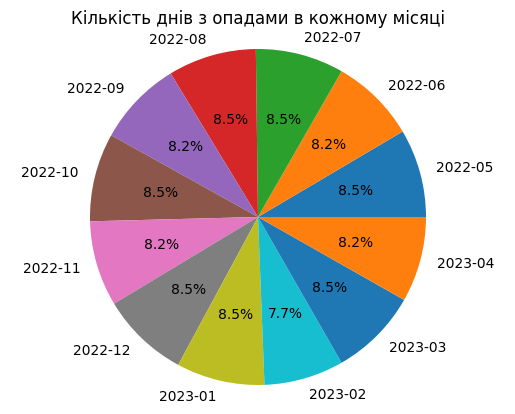

In [6]:
rainy_days = weather.loc[weather['опади'] != '0'].groupby(weather['період']).size()

plt.pie(rainy_days, labels=rainy_days.index, autopct='%1.1f%%')
plt.axis('equal')
plt.title('Кількість днів з опадами в кожному місяці')
plt.show()

## №7

<Figure size 1000x600 with 0 Axes>

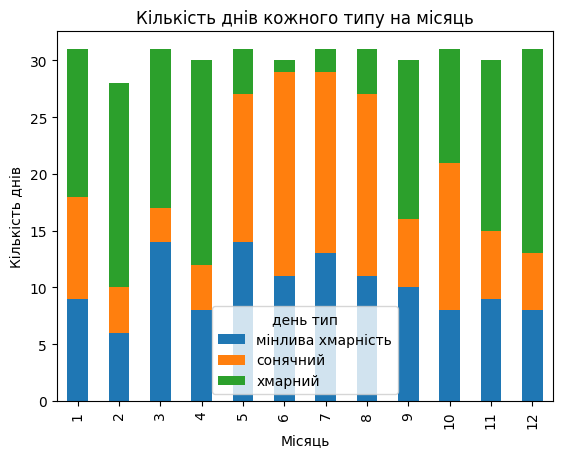

In [7]:
weather['хмарність'] = weather['хмарність'].str.replace('%', '').astype(float)

weather['день тип'] = weather.apply(lambda row: 'хмарний' if row['хмарність'] > 70 else 'сонячний' if row['хмарність'] < 35 else 'мінлива хмарність', axis=1)

days_per_month = weather.groupby([weather['період'].str.split('-').str[1].astype(int), 'день тип']).size().unstack()

plt.figure(figsize=(10, 6))
days_per_month.plot(kind='bar', stacked=True)
plt.xlabel('Місяць')
plt.ylabel('Кількість днів')
plt.title('Кількість днів кожного типу на місяць')
plt.show()

## №8

In [8]:
for month in range(1, 13):
    p = weather[weather['період'].str.split('-').str[1].astype(int) == month]
    rainfall = p[p['опади'].str.split(' ').str[0] != '-']
    
    sunnydays = p[p['хмарність'] < 30]
    
    if sunnydays.shape[0] > rainfall.shape[0]:
        print(f"Місяць {month}: {p['період'].iloc[0]}")

Місяць 1: 2023-01
Місяць 5: 2022-05
Місяць 6: 2022-06
Місяць 7: 2022-07
Місяць 8: 2022-08
Місяць 10: 2022-10


## №9

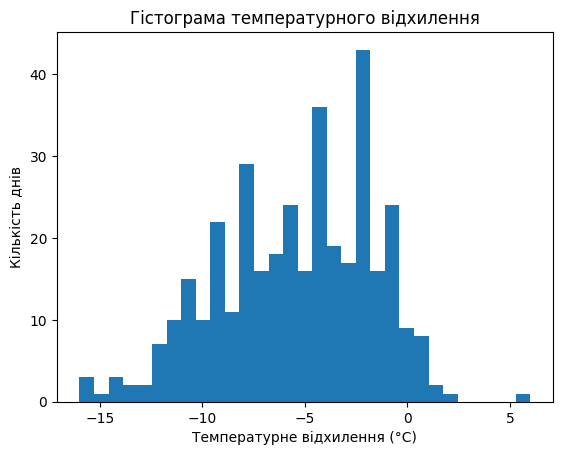

In [9]:
plt.hist(weather['нічна температура повітря'].str.split('°').str[0].astype(float) - weather['денна температура повітря'].str.split('°').str[0].astype(float), bins=31)
plt.xlabel('Температурне відхилення (°C)')
plt.ylabel('Кількість днів')
plt.title('Гістограма температурного відхилення')
plt.show()